<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan2/latihan2MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Persiapan: Import library


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display


## 1. Memuat dataset


In [2]:
# Lokasi file yang biasanya digunakan di Google Colab
nama_file = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
jalur_file = f"/content/{nama_file}"

# Jika file belum ada, minta pengguna mengunggah file CSV
if not os.path.exists(jalur_file):
    try:
        from google.colab import files
        print(f"Silakan unggah file: {nama_file}")
        berkas_diunggah = files.upload()
        kandidat_csv = [
            nama for nama in berkas_diunggah
            if nama.lower().endswith(".csv")
        ]
        if not kandidat_csv:
            raise FileNotFoundError(
                "Tidak ada file CSV yang diunggah. Unggah dataset Telco Customer Churn."
            )
        jalur_file = kandidat_csv[0]
    except ImportError as exc:
        raise FileNotFoundError(
            f"File {nama_file} tidak ditemukan. Letakkan file CSV di folder kerja."
        ) from exc

df = pd.read_csv(jalur_file)

# Ubah TotalCharges menjadi numerik; nilai kosong/berisi spasi menjadi NaN
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

if "Churn" not in df.columns:
    raise ValueError(
        "Kolom target 'Churn' tidak ditemukan. Pastikan file yang diunggah adalah dataset Telco Customer Churn."
    )

df = df.dropna(subset=["Churn"]).copy()

print("Ukuran dataset:", df.shape)
print("\nLima baris pertama:")
display(df.head())

print("\nDistribusi target Churn:")
print(df["Churn"].value_counts())
print("\nProporsi target (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


Ukuran dataset: (7043, 21)

Lima baris pertama:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Distribusi target Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Proporsi target (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## 2. Menentukan fitur dan membagi data (split + stratify)

In [3]:
# Pisahkan fitur (X) dan target (y)
kolom_dihapus = ["Churn", "customerID"]
X = df.drop(columns=kolom_dihapus, errors="ignore").copy()

# Target: No = 0, Yes = 1
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Target Churn memiliki label di luar kategori 'No' dan 'Yes'.")

# Pembagian data: 80% train, 20% test dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Jumlah seluruh data :", len(X))
print("Data training       :", X_train.shape)
print("Data testing        :", X_test.shape)

print("\nProporsi kelas pada seluruh data:")
print(y.value_counts(normalize=True).round(3))

print("\nProporsi kelas pada data training:")
print(y_train.value_counts(normalize=True).round(3))

print("\nProporsi kelas pada data testing:")
print(y_test.value_counts(normalize=True).round(3))


Jumlah seluruh data : 7043
Data training       : (5634, 19)
Data testing        : (1409, 19)

Proporsi kelas pada seluruh data:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Proporsi kelas pada data training:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Proporsi kelas pada data testing:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


## 3. Melatih Decision Tree dengan depth 1, 4, dan ∞

In [4]:
# Kenali tipe kolom dari data training
kolom_kategorikal = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

kolom_numerik = X_train.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Kolom numerik:", kolom_numerik)
print("\nKolom kategorikal:", kolom_kategorikal)

def buat_preprocessing():
    # Membuat objek preprocessing baru untuk setiap model
    return ColumnTransformer(
        transformers=[
            (
                "numerik",
                SimpleImputer(strategy="median"),
                kolom_numerik
            ),
            (
                "kategorikal",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]),
                kolom_kategorikal
            )
        ],
        remainder="drop"
    )

# Tiga tingkat kompleksitas sesuai instruksi praktikum
konfigurasi_model = [
    ("Depth 1", 1),
    ("Depth 4", 4),
    ("Depth ∞", None)
]

# Stratified 5-fold cross-validation pada data training
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

hasil = {}

for nama_model, depth in konfigurasi_model:
    model = Pipeline(steps=[
        ("preprocessing", buat_preprocessing()),
        ("tree", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    # Fit pada seluruh data training untuk memperoleh skor train/test
    model.fit(X_train, y_train)
    prediksi_train = model.predict(X_train)
    prediksi_test = model.predict(X_test)

    akurasi_train = accuracy_score(y_train, prediksi_train)
    akurasi_test = accuracy_score(y_test, prediksi_test)

    # Learning curve dihitung hanya dengan X_train dan y_train.
    # Setiap fold akan mem-fit preprocessing dari bagian train fold-nya sendiri.
    train_sizes, train_scores, valid_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    hasil[nama_model] = {
        "depth": depth,
        "train_sizes": train_sizes,
        "train_mean": train_scores.mean(axis=1),
        "train_std": train_scores.std(axis=1),
        "valid_mean": valid_scores.mean(axis=1),
        "valid_std": valid_scores.std(axis=1),
        "akurasi_train": akurasi_train,
        "akurasi_test": akurasi_test
    }

print("Pelatihan tiga model selesai.")


Kolom numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Pelatihan tiga model selesai.


## 4. Plot learning curve

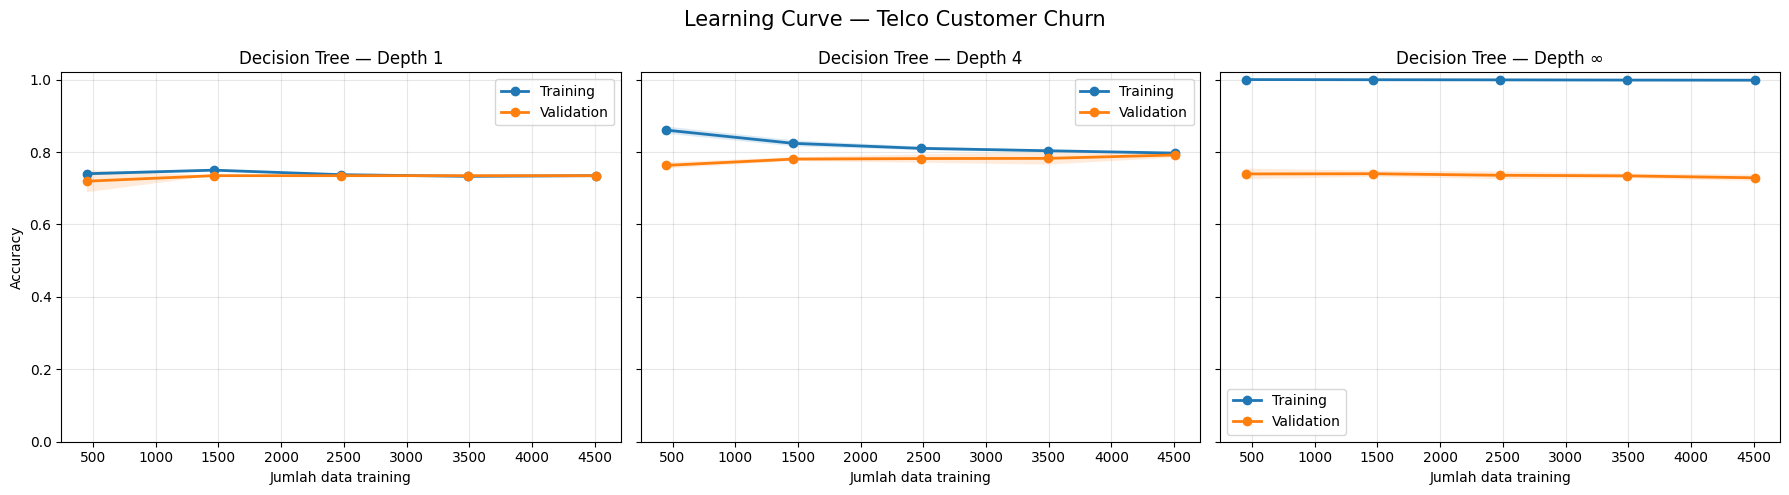

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (nama_model, _) in zip(axes, konfigurasi_model):
    data = hasil[nama_model]
    ukuran = data["train_sizes"]
    train_mean = data["train_mean"]
    train_std = data["train_std"]
    valid_mean = data["valid_mean"]
    valid_std = data["valid_std"]

    ax.plot(
        ukuran, train_mean,
        marker="o", linewidth=2,
        label="Training"
    )
    ax.fill_between(
        ukuran,
        np.maximum(0, train_mean - train_std),
        np.minimum(1, train_mean + train_std),
        alpha=0.15
    )

    ax.plot(
        ukuran, valid_mean,
        marker="o", linewidth=2,
        label="Validation"
    )
    ax.fill_between(
        ukuran,
        np.maximum(0, valid_mean - valid_std),
        np.minimum(1, valid_mean + valid_std),
        alpha=0.15
    )

    ax.set_title(f"Decision Tree — {nama_model}")
    ax.set_xlabel("Jumlah data training")
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Accuracy")
fig.suptitle("Learning Curve — Telco Customer Churn", fontsize=15)
plt.tight_layout()
plt.show()


## 5. Tabel hasil dan diagnosis tiga model

In [6]:
baris_tabel = []

for nama_model, _ in konfigurasi_model:
    data = hasil[nama_model]
    train_akhir = float(data["train_mean"][-1])
    valid_akhir = float(data["valid_mean"][-1])
    gap = train_akhir - valid_akhir

    baris_tabel.append({
        "Model": nama_model,
        "Train accuracy": round(data["akurasi_train"], 4),
        "Test accuracy": round(data["akurasi_test"], 4),
        "Learning curve train akhir": round(train_akhir, 4),
        "Learning curve validation akhir": round(valid_akhir, 4),
        "Gap train-validation": round(gap, 4)
    })

tabel_hasil = pd.DataFrame(baris_tabel)
display(tabel_hasil)


,Model,Train accuracy,Test accuracy,Learning curve train akhir,Learning curve validation akhir,Gap train-validation
0,Depth 1,0.7346,0.7346,0.7346,0.7346,-0.0000
1,Depth 4,0.7966,0.7921,0.7970,0.7918,0.0052
2,Depth ∞,0.9980,0.7289,0.9983,0.7288,0.2695


In [7]:
def diagnosis_model(train_curve, valid_curve):
    train_akhir = float(train_curve[-1])
    valid_akhir = float(valid_curve[-1])
    gap = train_akhir - valid_akhir

    # Kriteria indikatif untuk membantu membaca pola learning curve.
    if train_akhir < 0.75 and valid_akhir < 0.75 and abs(gap) <= 0.05:
        return (
            "Indikasi UNDERFITTING / bias tinggi: "
            "akurasi training dan validation sama-sama relatif rendah dan berdekatan."
        )
    elif train_akhir >= 0.90 and gap >= 0.10:
        return (
            "Indikasi OVERFITTING / variance tinggi: "
            "akurasi training tinggi, tetapi validation tertinggal jauh."
        )
    elif abs(gap) <= 0.05 and valid_akhir >= 0.75:
        return (
            "Relatif SEIMBANG / generalisasi cukup baik: "
            "skor training dan validation berdekatan dan validation relatif tinggi."
        )
    else:
        return (
            "Pola CAMPURAN: periksa grafik, besar gap, dan kestabilan validation. "
            "Belum cukup untuk memberi label tegas hanya dari satu angka."
        )

print("DIAGNOSIS LEARNING CURVE")
print("=" * 70)

for nama_model, _ in konfigurasi_model:
    data = hasil[nama_model]
    train_akhir = data["train_mean"][-1]
    valid_akhir = data["valid_mean"][-1]
    gap = train_akhir - valid_akhir

    print(f"\n{nama_model}")
    print(f"Training curve akhir   : {train_akhir:.3f}")
    print(f"Validation curve akhir : {valid_akhir:.3f}")
    print(f"Gap train-validation   : {gap:.3f}")
    print(diagnosis_model(data["train_mean"], data["valid_mean"]))

print("\nCatatan:")
print("- Diagnosis didasarkan pada learning curve, bukan kedalaman saja.")
print("- Gunakan test accuracy sebagai evaluasi akhir; jangan terus memilih model berdasarkan test set.")
print("- Ambang di atas bersifat indikatif, sehingga tetap periksa grafik dan konteks.")


DIAGNOSIS LEARNING CURVE

Depth 1
Training curve akhir   : 0.735
Validation curve akhir : 0.735
Gap train-validation   : -0.000
Indikasi UNDERFITTING / bias tinggi: akurasi training dan validation sama-sama relatif rendah dan berdekatan.

Depth 4
Training curve akhir   : 0.797
Validation curve akhir : 0.792
Gap train-validation   : 0.005
Relatif SEIMBANG / generalisasi cukup baik: skor training dan validation berdekatan dan validation relatif tinggi.

Depth ∞
Training curve akhir   : 0.998
Validation curve akhir : 0.729
Gap train-validation   : 0.270
Indikasi OVERFITTING / variance tinggi: akurasi training tinggi, tetapi validation tertinggal jauh.

Catatan:
- Diagnosis didasarkan pada learning curve, bukan kedalaman saja.
- Gunakan test accuracy sebagai evaluasi akhir; jangan terus memilih model berdasarkan test set.
- Ambang di atas bersifat indikatif, sehingga tetap periksa grafik dan konteks.
